[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/20_pytorch_essentials.ipynb)

# 20 · PyTorch Essentials: The Same Ideas, at Scale

**Part 3 — Deep learning** · Notebook 20 of 27

In notebook 19 we wrote a neural network by hand: forward pass, backward pass, gradient check, SGD loop. That's the best way to understand it, and the worst way to build anything big. Every new layer type would need its own hand-derived backward pass, and NumPy can't use a GPU.

**PyTorch** keeps the same ideas and automates the tedious parts. Its tensors are NumPy arrays that can live on a GPU; its **autograd** records every operation and computes all gradients for you (exactly the computation-graph engine we built in notebook 04, industrial-strength); and its `nn` and `optim` modules package layers, losses, and optimizers. This notebook learns PyTorch by rebuilding things we already understand, then trains real networks on **Fashion-MNIST**, 70,000 photos of clothing, and develops the habits that make deep learning work in practice: a standard training loop, sanity checks, regularization, and debugging.

**What you'll learn**

1. Tensors: NumPy with superpowers
2. Autograd: gradients for free (checked against notebook 04)
3. Linear regression four ways, from manual gradients to `nn` + `optim`
4. `nn.Module`: building networks out of parts
5. Data: Fashion-MNIST, `Dataset` and `DataLoader`
6. The training loop, and a first real model
7. Optimizers and learning-rate schedules, compared
8. Regularization in practice: dropout, weight decay, batch normalization
9. Debugging a network: the checklist that saves hours
10. GPUs, saving models, and reproducibility
11. Looking at what the model gets wrong

*Course map: this notebook supports CX 4240 lectures 11–13 and ISYE 4600 W10 (neural networks trained by backpropagation and SGD) by moving from hand-written NumPy to the tools used in practice; the autograd section revisits notebook 04 (CX 4240 lecture 11's worked backprop example).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, running on: {device}")
print("Ready ✓")

Setup complete ✓


PyTorch 2.14.1+cu130, running on: cpu
Ready ✓


> 💡 **Using a GPU on Colab:** `Runtime → Change runtime type → T4 GPU`, then re-run. Everything here also runs on the CPU (the default), just more slowly; the notebook trains on a 20,000-image subset by default so it finishes in a few minutes either way.

---
## 1. Tensors: NumPy with superpowers

A `torch.Tensor` is an n-dimensional array, like `np.ndarray`, with nearly the same operations: creation, indexing, broadcasting, matrix multiplication, reductions. Two additions matter: tensors can live on a **GPU**, and they can **track the operations** applied to them so that gradients can be computed.

In [2]:
a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("a =", a, "\nshape:", a.shape, " dtype:", a.dtype, " device:", a.device)
print("\nzeros / ones / random:", torch.zeros(2, 2).shape, torch.ones(3).shape, torch.randn(2, 3).shape)
print("arange and reshape:\n", torch.arange(12).reshape(3, 4))
b = torch.tensor([10.0, 20.0, 30.0])
print("\nbroadcasting a + b (b is added to every row):\n", a + b)
print("matrix product a @ aᵀ:\n", a @ a.T)
print("reductions: sum", a.sum().item(), " mean of each column", a.mean(dim=0))

# NumPy interop: .numpy() and torch.from_numpy share memory on the CPU
arr = np.arange(4.0); t = torch.from_numpy(arr); arr[0] = 99
print("\nshared memory: changing the NumPy array changed the tensor:", t)

a = tensor([[1., 2., 3.],
        [4., 5., 6.]]) 
shape: torch.Size([2, 3])  dtype: torch.float32  device: cpu

zeros / ones / random: torch.Size([2, 2]) torch.Size([3]) torch.Size([2, 3])
arange and reshape:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

broadcasting a + b (b is added to every row):
 tensor([[11., 22., 33.],
        [14., 25., 36.]])
matrix product a @ aᵀ:
 tensor([[14., 32.],
        [32., 77.]])
reductions: sum 21.0  mean of each column tensor([2.5000, 3.5000, 4.5000])

shared memory: changing the NumPy array changed the tensor: tensor([99.,  1.,  2.,  3.], dtype=torch.float64)


A few habits that prevent bugs:

- **Shapes first.** Most PyTorch errors are shape mismatches. Print `.shape` liberally. By convention the first dimension is the **batch**: a batch of 128 grayscale 28×28 images is a tensor of shape `(128, 1, 28, 28)`.
- **dtype.** Neural networks use `float32` (NumPy defaults to `float64`). Class labels for losses are `int64` (`torch.long`).
- **device.** Every tensor in an operation must be on the same device; `.to(device)` moves it.
- `.item()` turns a one-element tensor into a Python number.

---
## 2. Autograd: gradients for free

Set `requires_grad=True` on a tensor and PyTorch records every operation that uses it into a **computation graph**. Calling `.backward()` on a scalar result runs reverse-mode differentiation through that graph and stores $\partial(\text{result})/\partial(\text{tensor})$ in each leaf's `.grad`. That's notebook 04's `Value` engine, for tensors.

Let's check it against notebook 04's worked example from CX 4240 lecture 11: a tiny network $\ell = (o(Vh) - y)^2$, $h = \sigma(Wx)$, where we derived the gradients by hand.

In [3]:
torch.manual_seed(1)
x = torch.tensor([0.5, -1.0]); y = torch.tensor(1.0)
W = torch.randn(3, 2, requires_grad=True); V = torch.randn(3, requires_grad=True)

h = torch.sigmoid(W @ x)                 # hidden layer
o = torch.sigmoid(V @ h)                 # output
loss = (o - y) ** 2
loss.backward()                          # one call: all gradients

# The hand-derived gradients (notebook 04):  δ = 2(o − y)·o(1 − o)
with torch.no_grad():
    delta = 2 * (o - y) * o * (1 - o)
    dV = delta * h
    dW = torch.outer(delta * V * h * (1 - h), x)
print("∂ℓ/∂V  autograd:", V.grad.numpy().round(6), "\n       by hand: ", dV.numpy().round(6))
print("∂ℓ/∂W  autograd:\n", W.grad.numpy().round(6), "\n       by hand:\n", dW.numpy().round(6))

∂ℓ/∂V  autograd: [-0.143228 -0.098975 -0.134654] 
       by hand:  [-0.143228 -0.098975 -0.134654]
∂ℓ/∂W  autograd:
 [[ 0.052788 -0.105576]
 [-0.012154  0.024309]
 [ 0.035627 -0.071255]] 
       by hand:
 [[ 0.052788 -0.105576]
 [-0.012154  0.024309]
 [ 0.035627 -0.071255]]


Identical. Three autograd behaviors trip everyone up at least once:

In [4]:
w = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    (w ** 2).backward()
    print(f"after backward #{i + 1}: w.grad = {w.grad.item()}   (true gradient of w² at 3 is 6)")
w.grad.zero_()
print("after w.grad.zero_():", w.grad.item())

with torch.no_grad():                    # no graph is recorded: use for evaluation and for parameter updates
    z = w * 2
print("inside no_grad, z.requires_grad =", z.requires_grad)
print("w.detach() shares data but is cut out of the graph:", w.detach().requires_grad)

after backward #1: w.grad = 6.0   (true gradient of w² at 3 is 6)
after backward #2: w.grad = 12.0   (true gradient of w² at 3 is 6)
after backward #3: w.grad = 18.0   (true gradient of w² at 3 is 6)
after w.grad.zero_(): 0.0
inside no_grad, z.requires_grad = False
w.detach() shares data but is cut out of the graph: False


1. **Gradients accumulate.** Each `.backward()` *adds* to `.grad` (useful for summing gradients over several mini-batches, surprising otherwise). That's why every training loop calls `optimizer.zero_grad()` before `backward()`.
2. **`torch.no_grad()`** turns recording off: use it for evaluation (faster, less memory) and when updating parameters by hand (an update shouldn't itself be differentiated).
3. **`.detach()`** returns a tensor cut out of the graph, e.g. to plot a value or use it as a fixed target.

---
## 3. Linear regression four ways

The fastest way to learn the PyTorch idiom is to write the same model with less and less manual work. Data: $y = 3x - 2 + \text{noise}$.

In [5]:
torch.manual_seed(0)
Xl = torch.rand(200, 1) * 4 - 2; yl = 3 * Xl - 2 + 0.5 * torch.randn(200, 1)
results = {}

# (1) NumPy-style: manual gradients
w_, b_ = torch.zeros(1), torch.zeros(1)
for step in range(300):
    err = (Xl * w_ + b_) - yl
    w_ -= 0.1 * 2 * (err * Xl).mean(); b_ -= 0.1 * 2 * err.mean()
results["1. manual gradients"] = (w_.item(), b_.item())

# (2) autograd computes the gradients; we still update by hand
w_ = torch.zeros(1, requires_grad=True); b_ = torch.zeros(1, requires_grad=True)
for step in range(300):
    loss = ((Xl * w_ + b_ - yl) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w_ -= 0.1 * w_.grad; b_ -= 0.1 * b_.grad
        w_.grad.zero_(); b_.grad.zero_()
results["2. autograd + manual update"] = (w_.item(), b_.item())

# (3) an optimizer does the update and the zeroing
w_ = torch.zeros(1, requires_grad=True); b_ = torch.zeros(1, requires_grad=True)
opt = torch.optim.SGD([w_, b_], lr=0.1)
for step in range(300):
    loss = ((Xl * w_ + b_ - yl) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
results["3. autograd + torch.optim"] = (w_.item(), b_.item())

# (4) the idiomatic version: a layer, a loss function, an optimizer
model = nn.Linear(1, 1); loss_fn = nn.MSELoss(); opt = torch.optim.SGD(model.parameters(), lr=0.1)
for step in range(300):
    loss = loss_fn(model(Xl), yl)
    opt.zero_grad(); loss.backward(); opt.step()
results["4. nn.Linear + nn.MSELoss + optim"] = (model.weight.item(), model.bias.item())

# closed form (notebook 05) for reference
A = torch.cat([Xl, torch.ones_like(Xl)], 1); sol = torch.linalg.lstsq(A, yl).solution.squeeze()
results["normal equation (exact)"] = (sol[0].item(), sol[1].item())
pd.DataFrame(results, index=["slope w", "intercept b"]).T.round(4)

,slope w,intercept b
1. manual gradients,3.0237,-2.0397
2. autograd + manual update,3.0237,-2.0397
3. autograd + torch.optim,3.0237,-2.0397
4. nn.Linear + nn.MSELoss + optim,3.0237,-2.0397
normal equation (exact),3.0237,-2.0397


All four reach the least-squares answer. Version 4's three-line loop body is the pattern every PyTorch training loop follows, from this toy to large language models:

```python
loss = loss_fn(model(inputs), targets)   # forward
optimizer.zero_grad()                    # clear old gradients
loss.backward()                          # backward: autograd fills .grad
optimizer.step()                         # update the parameters
```

---
## 4. `nn.Module`: building networks out of parts

A model is a subclass of `nn.Module`: create the layers in `__init__`, describe the computation in `forward`. Any layer assigned as an attribute is registered automatically, so `model.parameters()` finds all its weights. Here's notebook 19's MLP:

In [6]:
class MLP(nn.Module):
    def __init__(self, sizes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        for n_in, n_out in zip(sizes[:-2], sizes[1:-1]):
            layers.append(nn.Linear(n_in, n_out))
            if batchnorm: layers.append(nn.BatchNorm1d(n_out))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(sizes[-2], sizes[-1]))       # last layer: raw scores ("logits"), no softmax
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x.flatten(1))                        # (batch, 1, 28, 28) → (batch, 784)

model = MLP([784, 256, 128, 10])
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\n{n_params:,} parameters:", [tuple(p.shape) for p in model.parameters()])

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

235,146 parameters: [(256, 784), (256,), (128, 256), (128,), (10, 128), (10,)]


`nn.Sequential` chains layers in order. Notice the last layer outputs raw scores (**logits**), not probabilities: `nn.CrossEntropyLoss` (or `F.cross_entropy`) applies log-softmax internally, which is more numerically stable than computing softmax and then its log (notebook 08's log-sum-exp trick). Apply `softmax` yourself only when you want to *read* probabilities.

---
## 5. Data: Fashion-MNIST

**Fashion-MNIST** (Xiao, Rasul & Vollgraf, 2017; Zalando) has 70,000 grayscale 28 × 28 photos of clothing in 10 classes, as a harder drop-in replacement for handwritten digits. We download the four files straight from the dataset's official GitHub repository (about 30 MB) and parse them with NumPy.

train: (60000, 1, 28, 28) test: (10000, 1, 28, 28)   pixel range: 0 – 255


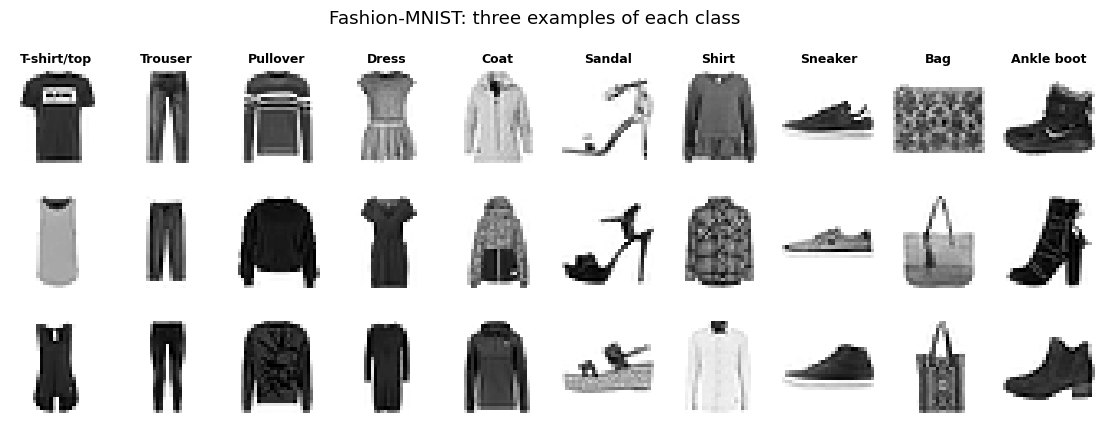

In [7]:
FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    Xtr = out[("train", "images")].reshape(-1, 1, 28, 28); Xte = out[("test", "images")].reshape(-1, 1, 28, 28)
    return Xtr, out[("train", "labels")], Xte, out[("test", "labels")]

Xtr_all, ytr_all, Xte_np, yte_np = load_fashion_mnist()
print("train:", Xtr_all.shape, "test:", Xte_np.shape, "  pixel range:", Xtr_all.min(), "–", Xtr_all.max())
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
for c in range(10):
    for r in range(3):
        img = Xtr_all[np.flatnonzero(ytr_all == c)[r], 0]
        axes[r, c].imshow(img, cmap="gray_r"); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
fig.suptitle("Fashion-MNIST: three examples of each class", y=1.0); plt.show()

Shirts, T-shirts, pullovers, and coats look alike at 28 × 28, which is what makes this dataset harder than digits.

### `Dataset` and `DataLoader`

PyTorch separates **what** the data is (`Dataset`: a length and a way to get item `i`) from **how** it's served (`DataLoader`: shuffling, batching, parallel loading). For data that fits in memory, `TensorDataset` wraps tensors directly. We normalize pixels to mean 0 and standard deviation 1 using statistics from the **training** set only (notebook 06's leakage rule), and hold out 5,000 training images for validation.

In [8]:
N_TRAIN = 20000                                  # set to 55000 on a GPU runtime for the full training set
rng_np = np.random.default_rng(0); perm = rng_np.permutation(len(Xtr_all))
val_idx, tr_idx = perm[:5000], perm[5000:5000 + N_TRAIN]
mean, std = Xtr_all[tr_idx].mean() / 255, Xtr_all[tr_idx].std() / 255
to_tensor = lambda X: (torch.tensor(X, dtype=torch.float32) / 255 - mean) / std

from torch.utils.data import TensorDataset, DataLoader
train_ds = TensorDataset(to_tensor(Xtr_all[tr_idx]), torch.tensor(ytr_all[tr_idx], dtype=torch.long))
val_ds = TensorDataset(to_tensor(Xtr_all[val_idx]), torch.tensor(ytr_all[val_idx], dtype=torch.long))
test_ds = TensorDataset(to_tensor(Xte_np), torch.tensor(yte_np, dtype=torch.long))
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)        # reshuffled every epoch
val_dl = DataLoader(val_ds, batch_size=1000); test_dl = DataLoader(test_ds, batch_size=1000)

xb, yb = next(iter(train_dl))
print(f"{len(train_ds):,} training / {len(val_ds):,} validation / {len(test_ds):,} test images")
print("one batch:", xb.shape, xb.dtype, yb.shape, yb.dtype, f"  (pixel mean {xb.mean():.2f}, std {xb.std():.2f})")

20,000 training / 5,000 validation / 10,000 test images
one batch: torch.Size([128, 1, 28, 28]) torch.float32 torch.Size([128]) torch.int64   (pixel mean 0.06, std 1.01)


---
## 6. The training loop

Here is the loop, written once and reused for the rest of the notebook (and, in spirit, in every deep learning project). Two details beyond the four-line core:

- `model.train()` / `model.eval()` switch layers that behave differently during training (dropout, batch norm; section 8).
- Evaluation runs under `torch.no_grad()`.

In [9]:
def evaluate(model, dl):
    model.eval(); total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
            correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

def fit(model, epochs=8, lr=1e-3, opt="adam", weight_decay=0.0, schedule=None, train_dl=train_dl, verbose=True, seed=0):
    torch.manual_seed(seed); model.to(device)
    optim = {"sgd": lambda: torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay),
             "momentum": lambda: torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay),
             "adam": lambda: torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay),
             "adamw": lambda: torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)}[opt]()
    sched = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=lr, total_steps=epochs * len(train_dl)) if schedule == "onecycle" else None
    hist = []
    for ep in range(epochs):
        model.train(); t0 = time.time(); run_loss, n = 0.0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)              # forward
            optim.zero_grad(); loss.backward(); optim.step()  # backward + update
            if sched: sched.step()
            run_loss += loss.item() * len(yb); n += len(yb)
        val_loss, val_acc = evaluate(model, val_dl)
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / n, val_loss=val_loss, val_acc=val_acc))
        if verbose: print(f"epoch {ep + 1:2d}  train loss {run_loss / n:.3f}  val loss {val_loss:.3f}  val acc {val_acc:.1%}  ({time.time() - t0:.1f}s)")
    return pd.DataFrame(hist)

torch.manual_seed(0)
mlp = MLP([784, 256, 128, 10])
print(f"before training: val loss {evaluate(mlp.to(device), val_dl)[0]:.3f}  (log 10 = {np.log(10):.3f}: a fair guess among 10 classes)")
h_mlp = fit(mlp, epochs=8)

before training: val loss 2.325  (log 10 = 2.303: a fair guess among 10 classes)


epoch  1  train loss 0.616  val loss 0.472  val acc 82.2%  (0.4s)


epoch  2  train loss 0.409  val loss 0.431  val acc 84.0%  (0.4s)


epoch  3  train loss 0.362  val loss 0.387  val acc 85.4%  (0.4s)


epoch  4  train loss 0.330  val loss 0.377  val acc 85.1%  (0.4s)


epoch  5  train loss 0.300  val loss 0.410  val acc 84.9%  (0.4s)


epoch  6  train loss 0.286  val loss 0.374  val acc 86.5%  (0.4s)


epoch  7  train loss 0.264  val loss 0.373  val acc 86.2%  (0.4s)


epoch  8  train loss 0.248  val loss 0.362  val acc 86.5%  (0.4s)


The loss before training is close to $\log 10 \approx 2.30$, exactly what cross-entropy gives when the model spreads probability evenly over 10 classes: a quick sanity check that the setup is right (section 9). After a few epochs the MLP gets around 87% of validation images right. Compare simple baselines:

In [10]:
from sklearn.linear_model import LogisticRegression
import warnings; warnings.filterwarnings("ignore", message="lbfgs failed to converge")
Xflat = train_ds.tensors[0].flatten(1).numpy(); Xvflat = val_ds.tensors[0].flatten(1).numpy()
t0 = time.time(); logreg = LogisticRegression(max_iter=300).fit(Xflat[:10000], train_ds.tensors[1].numpy()[:10000])
print(f"logistic regression (10k images):  val acc {logreg.score(Xvflat, val_ds.tensors[1].numpy()):.1%}  ({time.time() - t0:.0f}s)")
print(f"MLP 784-256-128-10:                val acc {h_mlp.val_acc.iloc[-1]:.1%}")

logistic regression (10k images):  val acc 81.2%  (13s)
MLP 784-256-128-10:                val acc 86.5%


Unlike the 8 × 8 digits in notebook 19, here the hidden layers clearly help: clothing categories aren't linearly separable in pixel space. (A convolutional network does better still, notebook 21.)

---
## 7. Optimizers and learning-rate schedules

`torch.optim` has all the optimizers from notebook 03. Let's race them on the same network and data, each at a typical learning rate for it. The `OneCycleLR` **schedule** warms the learning rate up and then anneals it down over training, a simple trick that often speeds training up.

SGD (lr 0.05)                final val acc 80.1%


SGD + momentum (lr 0.05)     final val acc 86.3%


Adam (lr 1e-3)               final val acc 86.5%


Adam + one-cycle schedule    final val acc 88.0%


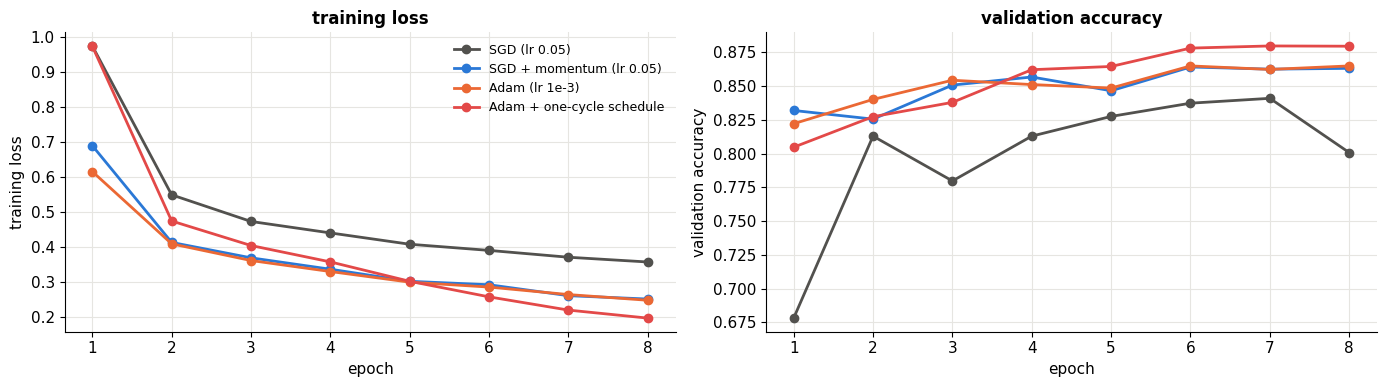

In [11]:
runs = {}
for name, opt_, lr_, sch in [("SGD (lr 0.05)", "sgd", 0.05, None), ("SGD + momentum (lr 0.05)", "momentum", 0.05, None),
                             ("Adam (lr 1e-3)", "adam", 1e-3, None), ("Adam + one-cycle schedule", "adam", 3e-3, "onecycle")]:
    torch.manual_seed(0); runs[name] = fit(MLP([784, 256, 128, 10]), epochs=8, lr=lr_, opt=opt_, schedule=sch, verbose=False)
    print(f"{name:28s} final val acc {runs[name].val_acc.iloc[-1]:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (name, h), col in zip(runs.items(), [C["muted"], C["blue"], C["orange"], C["red"]]):
    axes[0].plot(h.epoch, h.train_loss, "o-", color=col, label=name); axes[1].plot(h.epoch, h.val_acc, "o-", color=col, label=name)
axes[0].set(xlabel="epoch", ylabel="training loss", title="training loss"); axes[1].set(xlabel="epoch", ylabel="validation accuracy", title="validation accuracy")
axes[0].legend(fontsize=9); fig.tight_layout(); plt.show()

Plain SGD is the slowest; momentum and Adam reach low training loss much faster, which is why Adam (and its weight-decay variant AdamW) is the default starting point in deep learning. The schedule helps the final epochs settle into a good minimum. The *learning rate* matters more than the choice of optimizer, though, which brings us to the most useful tuning plot in deep learning.

### Finding a good learning rate

The **learning-rate range test** (Smith, 2015): train for a few hundred steps while increasing the learning rate exponentially from tiny to huge, recording the loss. The loss falls slowly at first, then quickly, then explodes. A good learning rate sits on the steep downhill part, roughly a factor of 10 below where the loss is lowest. 🎚️ **Then try a learning rate and see what training does:**

In [12]:
torch.manual_seed(0); probe = MLP([784, 256, 128, 10]).to(device); opt_p = torch.optim.Adam(probe.parameters(), lr=1e-6)
lrs = np.geomspace(1e-6, 1.0, 200); lr_losses = []; it_dl = iter(train_dl)
for lr_ in lrs:
    try: xb, yb = next(it_dl)
    except StopIteration: it_dl = iter(train_dl); xb, yb = next(it_dl)
    for g in opt_p.param_groups: g["lr"] = lr_
    loss = F.cross_entropy(probe(xb.to(device)), yb.to(device)); opt_p.zero_grad(); loss.backward(); opt_p.step()
    lr_losses.append(loss.item())
smooth = pd.Series(lr_losses).ewm(alpha=0.1).mean().values

lr_options = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
lr_runs = {lr_: fit(MLP([784, 256, 128, 10]), epochs=5, lr=lr_, verbose=False) for lr_ in lr_options}
def lr_demo(lr_index=2):
    lr_ = lr_options[lr_index]; h = lr_runs[lr_]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].semilogx(lrs, smooth, color=C["violet"]); axes[0].axvline(lr_, color=C["red"], ls="--", label=f"chosen lr = {lr_:g}")
    axes[0].set(ylim=(0, 3), xlabel="learning rate (increased every step)", ylabel="training loss (smoothed)", title="learning-rate range test"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_loss, "o-", label="training loss"); axes[1].plot(h.epoch, h.val_loss, "o-", label="validation loss")
    axes[1].set(ylim=(0, 2.5), xlabel="epoch", title=f"Adam with lr = {lr_:g}: final val acc {h.val_acc.iloc[-1]:.1%}"); axes[1].legend()
    fig.tight_layout(); plt.show()

interact(lr_demo, lr_index=IntSlider(value=2, min=0, max=len(lr_options) - 1, description="lr 1e-5…1e-1", readout=False));

At $10^{-5}$ training barely moves in five epochs; at $10^{-1}$ Adam's steps are so large that the loss stays high (or bounces around). The range test points at roughly $10^{-3}$ for Adam here, which is also the folklore default.

---
## 8. Regularization in practice

With 20,000 images and ~235,000 parameters, our MLP can overfit if trained long enough. Three tools, each a one-line change in PyTorch:

- **Dropout** (Srivastava et al., 2014): during training, zero each hidden unit's output with probability $p$ (and scale the rest by $1/(1-p)$). The network can't rely on any single unit, so it learns redundant, more robust features. At evaluation time (`model.eval()`) dropout is switched off. It behaves like training a large ensemble of thinned networks that share weights.
- **Weight decay**: the L2 penalty from notebook 07 and notebook 19. In `AdamW` it's applied directly to the weights (decoupled from the adaptive step), which works better with Adam.
- **Batch normalization** (Ioffe & Szegedy, 2015): standardize each layer's inputs to zero mean and unit variance over the mini-batch, then rescale with learned parameters. Training becomes faster and less sensitive to initialization and learning rate. In `eval()` mode it uses running averages instead of batch statistics.

To make overfitting visible, train on only 5,000 images for 30 epochs:

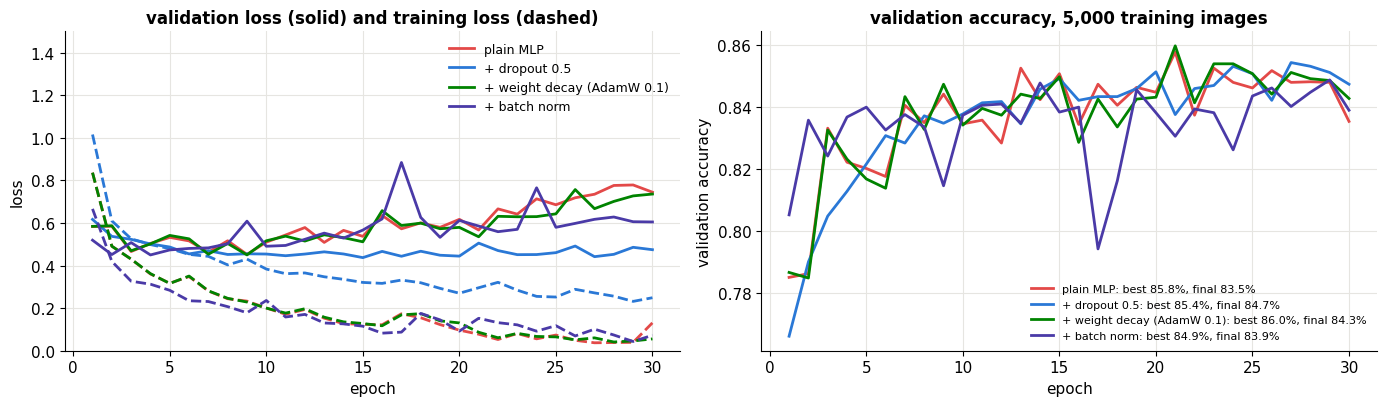

In [13]:
small_dl = DataLoader(TensorDataset(*[t[:5000] for t in train_ds.tensors]), batch_size=128, shuffle=True)
reg_cfg = {"plain MLP": dict(model=lambda: MLP([784, 512, 512, 10]), wd=0.0, opt="adam"),
           "+ dropout 0.5": dict(model=lambda: MLP([784, 512, 512, 10], dropout=0.5), wd=0.0, opt="adam"),
           "+ weight decay (AdamW 0.1)": dict(model=lambda: MLP([784, 512, 512, 10]), wd=0.1, opt="adamw"),
           "+ batch norm": dict(model=lambda: MLP([784, 512, 512, 10], batchnorm=True), wd=0.0, opt="adam")}
reg_hist = {}
for name, cfg in reg_cfg.items():
    torch.manual_seed(0); reg_hist[name] = fit(cfg["model"](), epochs=30, lr=1e-3, opt=cfg["opt"], weight_decay=cfg["wd"], train_dl=small_dl, verbose=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, h), col in zip(reg_hist.items(), [C["red"], C["blue"], C["green"], C["violet"]]):
    axes[0].plot(h.epoch, h.train_loss, color=col, ls="--"); axes[0].plot(h.epoch, h.val_loss, color=col, label=name)
    axes[1].plot(h.epoch, h.val_acc, color=col, label=f"{name}: best {h.val_acc.max():.1%}, final {h.val_acc.iloc[-1]:.1%}")
axes[0].set(ylim=(0, 1.5), xlabel="epoch", ylabel="loss", title="validation loss (solid) and training loss (dashed)")
axes[1].set(xlabel="epoch", ylabel="validation accuracy", title="validation accuracy, 5,000 training images"); axes[0].legend(fontsize=9); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

The plain MLP drives its training loss to almost zero while its validation loss turns around after a few epochs and keeps climbing: textbook overfitting (the network grows more and more confident, including about its mistakes). Dropout keeps the validation loss much lower and steadier. Batch norm and weight decay (at this strength) don't stop the overfitting here: batch norm's main benefit is faster, more stable optimization of deep networks rather than regularization, and weight decay would need to be stronger or combined with early stopping. Note that validation *accuracy* barely separates the four (all end around 84–86%, within seed-to-seed noise) even though validation *loss* differs a lot: overconfidence hurts the loss long before it flips predictions, and the loss is what tells you a model's probabilities can't be trusted. In practice you combine these tools and use **early stopping**: keep the weights from the epoch with the best validation score.

---
## 9. Debugging a network: a checklist

Neural network bugs rarely crash: the code runs and the model just learns badly. Karpathy's *A Recipe for Training Neural Networks* is the classic guide. The most useful checks:

1. **Check the loss at initialization.** For $K$ balanced classes, cross-entropy should start near $\log K$ (we saw 2.30 above). Much higher means the initial outputs are overconfident; check initialization and that you aren't applying softmax twice.
2. **Overfit a single batch.** A working model and training loop can drive the loss on one small batch to nearly zero. If it can't, there's a bug (wrong labels, a missing `zero_grad`, a frozen layer, a learning rate off by 100×).
3. **Watch gradient norms** per layer: zeros mean dead units or a detached graph; huge values mean explosion (clip them, notebook 22).
4. **Visualize the data** going into the model, after all preprocessing.
5. **Start simple**, then add complexity one piece at a time.

Here's check 2, and what a classic bug looks like:

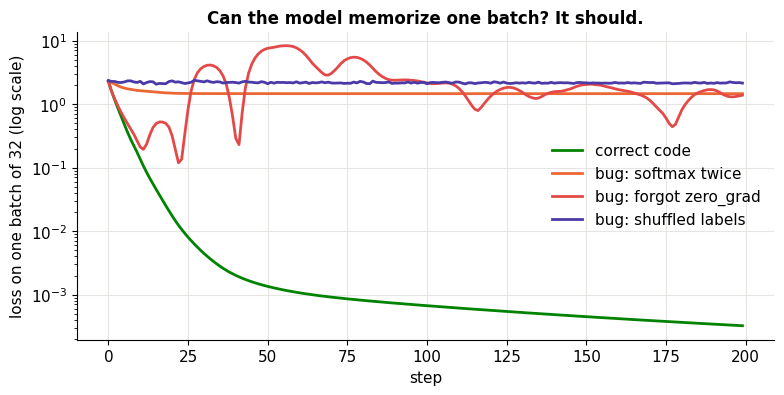

In [14]:
xb1, yb1 = next(iter(train_dl)); xb1, yb1 = xb1[:32].to(device), yb1[:32].to(device)
def overfit_one_batch(bug=None, steps=200):
    torch.manual_seed(0); m = MLP([784, 256, 10]).to(device); opt = torch.optim.Adam(m.parameters(), lr=1e-3); losses = []
    for s in range(steps):
        logits = m(xb1)
        if bug == "softmax twice": logits = F.softmax(logits, 1)      # cross_entropy already applies (log-)softmax
        loss = F.cross_entropy(logits, yb1 if bug != "shuffled labels" else yb1[torch.randperm(32)])
        if bug != "forgot zero_grad": opt.zero_grad()
        loss.backward(); opt.step(); losses.append(loss.item())
    return losses
fig, ax = plt.subplots(figsize=(9, 4))
for bug, col in [(None, C["green"]), ("softmax twice", C["orange"]), ("forgot zero_grad", C["red"]), ("shuffled labels", C["violet"])]:
    ax.plot(overfit_one_batch(bug), color=col, label="correct code" if bug is None else f"bug: {bug}")
ax.set(yscale="log", xlabel="step", ylabel="loss on one batch of 32 (log scale)", title="Can the model memorize one batch? It should."); ax.legend()
plt.show()

The correct code drives the loss toward zero within a hundred steps. Each bug leaves a fingerprint: applying softmax before `cross_entropy` squashes the logits into [0, 1], so the loss can't go below about 1.5; forgetting `zero_grad` accumulates stale gradients, so the effective steps grow huge and the loss jumps around; reshuffling labels every step means there is no consistent pattern to learn. Two minutes with this test catches bugs that otherwise cost days.

---
## 10. GPUs, saving models, and reproducibility

**GPUs.** Write device-agnostic code (`model.to(device)`, `xb.to(device)`, as we did throughout) and the same notebook runs on a CPU or a GPU. GPUs pay off for large matrix multiplications and convolutions:

In [15]:
for n in [256, 1024, 4096]:
    A_ = torch.randn(n, n); t0 = time.time(); _ = A_ @ A_; cpu_t = time.time() - t0
    if device == "cuda":
        Ag = A_.to(device); torch.cuda.synchronize(); _ = Ag @ Ag; torch.cuda.synchronize()
        t0 = time.time(); _ = Ag @ Ag; torch.cuda.synchronize(); gpu_t = time.time() - t0
        print(f"{n}×{n} matrix product:  CPU {cpu_t * 1000:7.1f} ms   GPU {gpu_t * 1000:6.2f} ms")
    else:
        print(f"{n}×{n} matrix product:  CPU {cpu_t * 1000:7.1f} ms   (no GPU in this runtime; switch to a GPU runtime to compare)")

256×256 matrix product:  CPU     0.2 ms   (no GPU in this runtime; switch to a GPU runtime to compare)
1024×1024 matrix product:  CPU     7.5 ms   (no GPU in this runtime; switch to a GPU runtime to compare)


4096×4096 matrix product:  CPU   521.3 ms   (no GPU in this runtime; switch to a GPU runtime to compare)


(GPU operations run asynchronously, so timing them needs `torch.cuda.synchronize()`; the first call also includes one-time setup, which is why we warm up first.)

**Saving and loading.** Save the `state_dict` (a dictionary of parameter tensors), not the whole Python object:

In [16]:
torch.save(mlp.state_dict(), "mlp_fashion.pt")
restored = MLP([784, 256, 128, 10]).to(device); restored.load_state_dict(torch.load("mlp_fashion.pt", map_location=device))
print("restored model's validation accuracy:", f"{evaluate(restored, val_dl)[1]:.1%}", " (same as the original:", f"{evaluate(mlp, val_dl)[1]:.1%})")
print("file size:", f"{os.path.getsize('mlp_fashion.pt') / 1e6:.2f} MB")

restored model's validation accuracy: 86.5%  (same as the original: 86.5%)
file size: 0.94 MB


**Reproducibility.** Random initialization, shuffling, and dropout all draw random numbers. `torch.manual_seed(…)` (plus NumPy's seed) makes a CPU run repeatable; on GPUs some operations are nondeterministic unless you also set `torch.use_deterministic_algorithms(True)`. Run important comparisons over **several seeds**: differences of a few tenths of a percent between models are often within seed-to-seed noise.

---
## 11. Looking at what the model gets wrong

Finally, evaluate on the **test set** once, at the end, and look at the errors:

final MLP: test accuracy 87.4% (validation 87.8%)


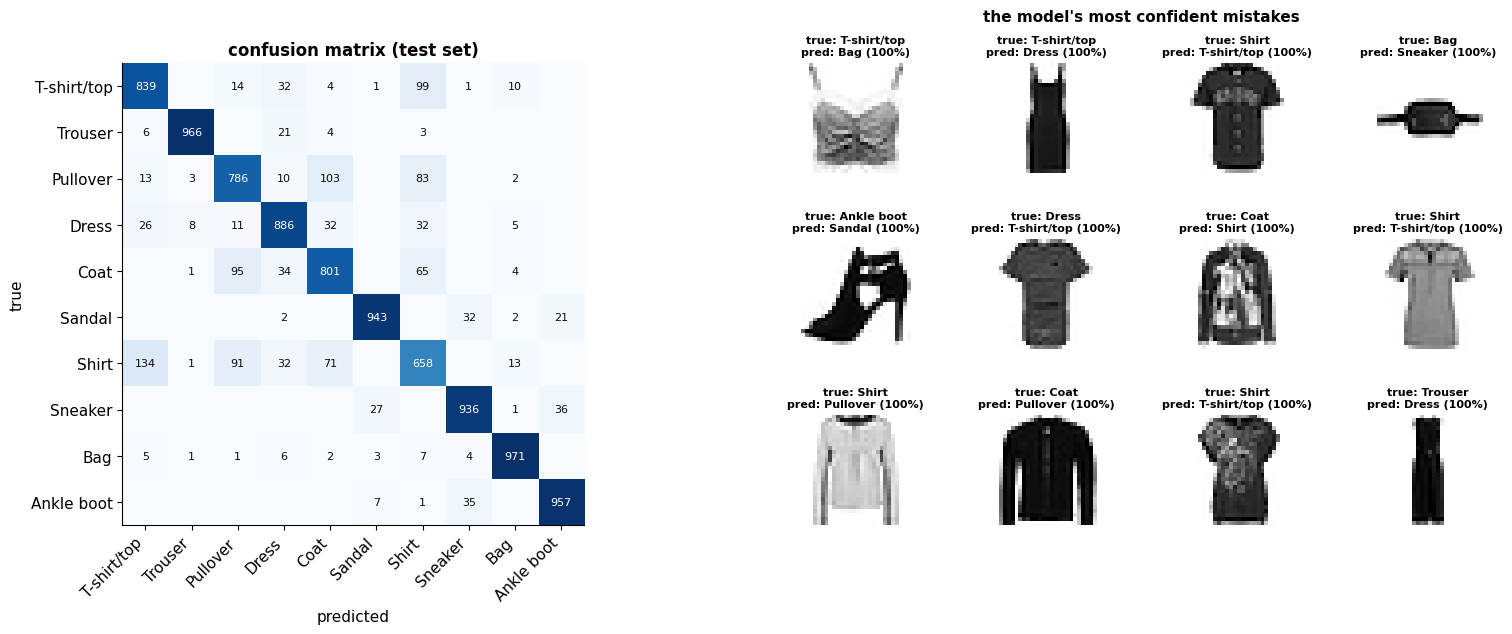

In [17]:
best = MLP([784, 512, 256, 10], dropout=0.3); h_best = fit(best, epochs=10, lr=2e-3, opt="adamw", weight_decay=0.01, schedule="onecycle", verbose=False)
test_loss, test_acc = evaluate(best, test_dl)
print(f"final MLP: test accuracy {test_acc:.1%} (validation {h_best.val_acc.iloc[-1]:.1%})")

best.eval()
with torch.no_grad():
    logits = torch.cat([best(xb.to(device)).cpu() for xb, _ in test_dl]); probs = logits.softmax(1); pred = probs.argmax(1).numpy()
cm = pd.crosstab(pd.Series(yte_np, name="true"), pd.Series(pred, name="predicted")).values
fig = plt.figure(figsize=(17, 6))
ax = fig.add_subplot(1, 2, 1)
cm_norm = cm / cm.sum(1, keepdims=True)
ax.imshow(cm_norm, cmap="Blues"); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm_norm[i, j] > 0.5 else C["ink"])
ax.set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES, xlabel="predicted", ylabel="true", title="confusion matrix (test set)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
wrong = np.flatnonzero(pred != yte_np); conf_wrong = wrong[np.argsort(-probs[wrong].max(1).values.numpy())][:12]
gs_ = fig.add_gridspec(3, 4, left=0.55, right=0.98, hspace=0.6)
for k, i in enumerate(conf_wrong):
    a_ = fig.add_subplot(gs_[k // 4, k % 4]); a_.imshow(Xte_np[i, 0], cmap="gray_r"); a_.axis("off")
    a_.set_title(f"true: {CLASSES[yte_np[i]]}\npred: {CLASSES[pred[i]]} ({probs[i].max():.0%})", fontsize=8)
fig.text(0.765, 0.95, "the model's most confident mistakes", ha="center", fontsize=11, weight="bold")
plt.show()

The confusion matrix shows where the difficulty lives: **shirts** get confused with T-shirts, pullovers, and coats, and pullovers with coats; footwear and trousers are nearly perfect. Several of the most confident "mistakes" are genuinely ambiguous at 28 × 28 pixels, and a few look mislabeled. An MLP flattens each image into 784 unrelated numbers, throwing away the fact that neighboring pixels form edges and shapes. Building that structure back in is the job of convolutional networks, next.

---
## 12. Summary

| Task | PyTorch |
|---|---|
| arrays on CPU/GPU | `torch.tensor`, `.to(device)`, `.shape`, `.item()` |
| gradients | `requires_grad=True`, `loss.backward()`, `.grad`; `torch.no_grad()`, `.detach()` |
| models | subclass `nn.Module`; `nn.Linear`, `nn.ReLU`, `nn.Sequential`, `nn.Dropout`, `nn.BatchNorm1d` |
| losses | `F.cross_entropy` (takes logits), `nn.MSELoss` |
| optimizers | `torch.optim.SGD(momentum=…)`, `Adam`, `AdamW`, `lr_scheduler.OneCycleLR` |
| data | `TensorDataset` / custom `Dataset`, `DataLoader(batch_size, shuffle)` |
| the loop | `loss = …; optimizer.zero_grad(); loss.backward(); optimizer.step()`; `model.train()` / `model.eval()` |
| saving | `torch.save(model.state_dict(), path)`, `model.load_state_dict(torch.load(path))` |

**Habits:** check the loss at initialization, overfit one batch, find the learning rate with a range test, watch validation loss (not just accuracy), regularize (dropout, weight decay, batch norm, early stopping), touch the test set once.

### ✏️ Exercises

1. Re-implement notebook 19's `MLP` (forward and backward by hand) and verify its gradients against PyTorch autograd on random data.
2. Write a custom `Dataset` class for Fashion-MNIST that applies a random horizontal flip to each training image. Does augmentation help the MLP on 5,000 images?
3. Implement early stopping inside `fit`: keep a copy of the `state_dict` from the best validation epoch and restore it at the end.
4. Use `torch.nn.utils.clip_grad_norm_` and plot the per-layer gradient norms during training of the 12-layer sigmoid network from notebook 19, rebuilt in PyTorch.
5. Replace ReLU with sigmoid in the MLP and retrain with SGD. What happens to the training curve, and why (notebook 19, section 10)?
6. Train the same configuration with 5 different seeds and report the mean and standard deviation of test accuracy. Is the difference between dropout and no dropout in section 8 larger than the seed noise?

### References

- PyTorch documentation and tutorials (pytorch.org); A. Paszke et al., *PyTorch: An Imperative Style, High-Performance Deep Learning Library*, NeurIPS (2019).
- H. Xiao, K. Rasul & R. Vollgraf, *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms* (2017).
- D. Kingma & J. Ba, *Adam* (2015); I. Loshchilov & F. Hutter, *Decoupled Weight Decay Regularization (AdamW)* (2019).
- N. Srivastava et al., *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR (2014); S. Ioffe & C. Szegedy, *Batch Normalization* (2015).
- L. Smith, *Cyclical Learning Rates for Training Neural Networks* (2015) and *Super-Convergence* (2018).
- A. Karpathy, *A Recipe for Training Neural Networks* (blog, 2019).

**Next → [21 · Convolutional Neural Networks](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/21_cnns.ipynb)**